# Lab 1B - Robot Navigation and Motor Control

**Course:** GPA778 - Embedded Algorithms in Robotics

---

## Table of Contents

1. [Introduction](#introduction)
2. [Objectives](#objectives)
3. [Part 1: Introduction to Pigpio](#partie1)
4. [Part 2: jerro_driver Package](#partie2)
5. [Part 3: Motor Control with PWM](#partie3)
   - [System Architecture](#architecture)
   - [cmd_vel_node Code](#mainnode)
7. [Demonstration](#demo)

<a id='introduction'></a>
## Introduction

In this lab, we will learn how to:
- Control the motors of the Jerro mobile robot through its interfaces
- Learn the basic principles of the Pigpio library
- Interface with packages provided by the ROS community

This lab builds on the knowledge acquired in Lab 1A concerning GPIOs and ROS2.

<a id='objectives'></a>
## Objectives

By the end of this lab, you will be able to:

- ✓ Control the robot's speed through a terminal interface
- ✓ Read encoder data to determine the angular speed of the wheels
- ✓ Create a ROS2 node that subscribes to and publishes on multiple topics

<a id='partie1'></a>
## Part 1: Introduction to Pigpio
[Pigpio](https://abyz.me.uk/rpi/pigpio/) is a C-language library that allows you to control the GPIOs (General Purpose Input Outputs) of a Raspberry Pi. This library was installed when the Raspberry Pi image was created and is stored in `~/pigpio`. Unlike the WiringPi library, which has been obsolete since 2023, Pigpio uses GPIOs identified by their Broadcom (BCM) numbers. By running the command `gpio readall`, you get the following result:


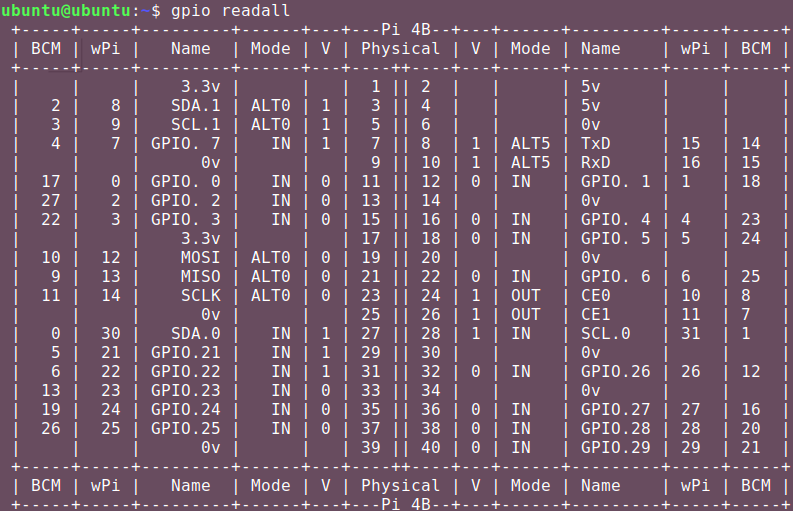

Starting from the center of this figure and looking at the columns in pairs toward the outside of the figure, the first two columns, “Physical,” indicate the pin numbers found directly on the RPI's “header”-type connector. Thus, you can see, unsurprisingly, that the numbers follow an ordered sequence. The next pair of columns, “V,” simply indicates the voltage logic level (read or written) found on each of these pins. Thus, a “0” means that the voltage is 0 Volts, while a logic “1” means that the voltage is 3.3 Volts on the pin. The next pair of columns, “Mode,” indicates whether the pins are configured as input (`IN`), output (`OUT`), or another mode, which can range from `ALT0` to `ALT5`¹². The following pair, labeled “Name,” is simply the identification name assigned to each pin by the RPI. These pin names will never change, even if we reconfigure some of them. The last pairs of columns are the most important for today's lab. The “wPi” columns designate the reference numbers assigned to each configurable pin¹³ when using the “WiringPi” library to interact with them. Finally, the last pair of columns, labeled “BCM,” refers to “Broadcom,” the company that manufactures the CPU at the heart of the RPI. Thus, the numbers in this last pair of columns refer to the pin identification numbers used by the CPU manufacturer. Therefore, as you will see many times today and in the coming weeks, we will use one or the other of these two reference systems to interact with GPIOs: either the WiringPi library system or the lower-level system used by Broadcom. At any time, feel free to use the `gpio read all` command to check the configurations applied to the pins and the voltage values being read/written.

To interface with programs and GPIO pins at all times, Pigpio uses a “daemon.” This is a process that runs in the background to provide certain services to the system and/or the user. **Each time the Raspberry Pi starts, this daemon must be launched using the command**:
```bash
sudo pigpiod
```

<a id='partie2'></a>
## Part 2: jerro_driver Package
The **jerro_drivers** package allows you to interface with the various sensors and actuators of the Jerro robot. This package contains four ROS2 nodes:
- `Encodeur_publisher`: This node reads the quadrature encoders of the two motors through Pigpio using GPIO callbacks and a transition table for decoding. It publishes the encoder counts (ticks) of both motors at 50 Hz, with direction inversion handling to match the actual direction of rotation.
- `Motor_pid_controller`: This node implements a PID controller for the two motors by reading the encoders, calculating the current speed, and applying PID control to reach a target speed in ticks/sec using hardware PWM at 1 kHz. It also supports a direct PWM mode and includes a PID gain auto-tuning system through an action server using the Ziegler-Nichols method.
- `Servomotor`: This node controls a servo motor on GPIO 25 using hardware PWM at 50 Hz with pigpio. It exposes a ROS2 service for positioning the servo by sending a pulse width in microseconds (1000–2000 µs); the servo automatically starts in the center position (1500 µs).

- `Centrale_inertielle`: This node reads data from an MPU6050 inertial measurement unit (accelerometer + gyroscope) via I2C using wiringPi. It publishes raw IMU data on `/imu/data_raw`, reoriented data on `/imu/data_reoriented`, calculates a calibration bias at startup, and broadcasts a TF2 transform between `base_link` and `imu_frame` at 20 Hz.

### Installing the jerro_drivers package

The jerro_drivers package must be downloaded, compiled, and run on your RPi.
This package is in the CoRo lab's GitHub repository:

https://github.com/Lab-CORO/jerro

To download it, you can use the `git clone` command in your terminal.
```bash
cd ~/ros2_ws/src
git clone https://github.com/Lab-CORO/jerro
```
Once the repository has been cloned, you can compile your ROS environment. You may have noticed that there are other packages in this repository; they will be presented and used in the upcoming labs.

PS: You may need to compile the jerro_msgs package before the others. To do this, I invite you to read the `colcon build` documentation:
```bash
colcon build -h
```

### Verifying the jerro_drivers package

To verify that the package is working correctly, run:

In [ ]:
# In one terminal
ros2 launch jerro_drivers motor_control.launch.py

# In another terminal
ros2 topic pub --once /motor/motor_RT_cmd jerro_msgs/msg/MotorSpeed "{motor_speed_a: 100.0, motor_speed_b: 100.0}"

ros2 topic echo /encoder_a

You should see the value of encoder A increasing.

<a id='partie4'></a>
## Part 4: Creating a Node to Control the Robot

### Exercise Overview
For a user or a trajectory planner to control a robot, it is useful to transmit speed commands through a direction vector rather than the speed of each motor. For this purpose, ROS2 provides a message type called [`Twist`](https://docs.ros2.org/galactic/api/geometry_msgs/msg/Twist.html). The `teleop_twist_keyboard` package provides a user interface for controlling the robot:

```bash
ubuntu@ubuntu:~/$ ros2 run teleop_twist_keyboard teleop_twist_keyboard

This node takes keypresses from the keyboard and publishes them
as Twist/TwistStamped messages. It works best with a US keyboard layout.
---------------------------
Moving around:
   u    i    o
   j    k    l
   m    ,    .

For Holonomic mode (strafing), hold down the shift key:
---------------------------
   U    I    O
   J    K    L
   M    <    >

t : up (+z)
b : down (-z)

anything else : stop

q/z : increase/decrease max speeds by 10%
w/x : increase/decrease only linear speed by 10%
e/c : increase/decrease only angular speed by 10%

CTRL-C to quit

currently:	speed 0.50	turn 1.00

```
In this exercise, you are asked to create a ROS2 node in Python to transform the user's speed commands, transmitted on the `/cmd_vel` topic by the `teleop_twist_keyboard` node, into commands for each motor. In addition, you will need to display the current speed of each wheel to validate that the PID controller is working correctly.

### Detailed Step-by-Step Description

#### Step 1: Creating the Package and Python Node
This first step consists of setting up the basic structure of your control node.

- **Create a new ROS2 package**: Create a dedicated package: `jerro_navigation`. The package must include the necessary dependencies: `rclpy`, `geometry_msgs`, `std_msgs`, and `jerro_msgs`.
```bash
ros2 pkg create --build-type ament_python jerro_navigation --dependencies rclpy geometry_msgs std_msgs  jerro_msgs
```

- **Create the node file**: Create a Python file (e.g., `twist_to_motors.py`) that will contain all the command-conversion logic. This file will be placed in the subfolder bearing the package name.

- **Configure the entry point**: In the `setup.py` file, add an entry to `console_scripts` to allow the node to be launched with the `ros2 run` command (as seen in Lab 1A).

#### Step 2: Configuring Subscribers and Publishers
This step defines how your node will communicate with the rest of the ROS2 system.

**Subscribers (inputs — what the node receives):**
- **Topic `/cmd_vel`**: This topic receives speed commands from the user or the trajectory planner. The message type is `geometry_msgs/Twist`, which contains a linear velocity (in m/s) and an angular velocity (in rad/s). Here is how to import the message type in Python:
```python
from geometry_msgs.msg import Twist
```

- **Topic `/encoder_a`**: This topic publishes data from the left wheel encoder. This data allows you to measure the actual rotation of the wheel and therefore determine its effective speed. You will use this information to verify that the motors correctly follow the commands.

- **Topic `/encoder_b`**: Identical to `/encoder_a`, but for the right wheel. Reading both encoders simultaneously makes it possible to precisely determine the robot's movement. The message type is `std_msgs/Int32`.
```python
from std_msgs.msg import Int32
```

**Publisher (output — what the node sends):**
- **Topic `/motor/set_speed`**: On this topic, you will publish the speed commands for each motor individually. These commands are generally expressed in ticks per second (depending on encoder resolution) or in PWM, depending on your hardware configuration. This message is not a predefined type. It was created in the `jerro_msgs` package.
```python
from jerro_msgs.msg import MotorSpeed
```

#### Step 3: Implementing Callback Functions
Callbacks are functions that execute automatically when a message arrives on a topic.

- **Callback for `/cmd_vel`**: This function is called whenever a new Twist command arrives. It must:
  - Extract the linear (`msg.linear.x`) and angular (`msg.angular.z`) velocity values
  - Call the conversion functions to obtain the individual wheel speeds
  - Publish the commands on `/motor/set_speed`

- **Callback for `/encoder_a`**: This function receives data from the left encoder and calculates the actual speed of that wheel. It allows you to monitor whether the motor is correctly following the command.

- **Callback for `/encoder_b`**: Identical for the right wheel. By comparing the actual speeds with the commands, you can diagnose control problems.

#### Step 4: Converting Speeds (Twist → Motors)
This is the central mathematical step where you convert the global commands into individual commands.

**Physical parameters to measure on the robot:**
- **Wheel radius**: `r` (in meters) — Measure the diameter of a wheel with a measuring tape and divide it by 2. Be precise, because an error here will propagate through all calculations.

- **Distance between the wheels**: `l` (in meters) — Measure the distance between the centers of contact of the two wheels on the ground. This is the width of the robot's wheelbase.

- **Encoder resolution**: Number of ticks per complete wheel revolution (e.g., 1024 ticks/revolution). For our encoder with the current configuration, it is 632.8 ticks/revolution.

**Differential-drive kinematic formulas:**

For a differential-drive robot, the left and right wheel velocities are calculated from the linear velocity `v` and angular velocity `ω`:
```
v_left = v_linear - (ω_angular × l) / 2
v_right = v_linear + (ω_angular × l) / 2
```

**Explanation:**
- If `ω = 0` (no rotation), both wheels have the same speed: the robot moves straight ahead
- If `v = 0` (no forward motion), the wheels rotate in opposite directions: the robot pivots in place
- If `ω > 0`, the right wheel moves faster: the robot turns left

**Conversion m/s → ticks/s:**

The calculated speeds are in m/s, but the motors require commands in ticks/s:
```
ticks_per_second = (speed_m/s × ticks_per_revolution) / (2π × radius)
```

**Calculation explanation:**
- The circumference of a wheel is `2π × radius` (distance traveled in one revolution)
- In one revolution, the encoder generates `ticks_per_revolution` pulses
- Therefore: `speed_m/s` divided by `2π × radius` gives revolutions/s
- Multiplying by `ticks_per_revolution` gives ticks/s

Then publish these values on `/motor/set_speed` in the format expected by your motor controller.

#### Step 5: Calculating and Displaying the Actual Wheel Speed
This step allows you to validate that everything is working correctly by comparing commands and measurements.

**In the encoder callbacks:**

- **Reading the data**: The encoders generally publish the number of ticks since the last message and a timestamp.

- **Calculating speed in ticks/s**:
```
  speed_ticks/s = (current_ticks - previous_ticks) / (current_time - previous_time)
```

- **Converting to m/s**: Use the inverse formula from Step 4:
```
  speed_m/s = (ticks/s × 2π × radius) / ticks_per_revolution
```

- **Display using logging**: Use `self.get_logger().info()` to display:
  - The commanded speed (the one you sent)
  - The measured speed (the one calculated from the encoder)
  - The error between the two (command - measurement)

**Example output:**
```python
self.get_logger().info(f"Left wheel - Command: {v_command:.3f} m/s, Measurement: {v_measurement:.3f} m/s, Error: {error:.3f} m/s")
```

This information is crucial for diagnosing problems: if the error is large, the PID needs to be adjusted.

<!-- #### Step 6 (optional): Adjusting the PID Controller
If you find that the actual speeds do not closely follow the commands, the PID controller needs to be optimized.

**Diagnosing common problems:**
- **Steady-state error** (stabilized speed below the command): Increase the integral gain `Ki`
- **Oscillations** (speed overshoots and then decreases): Reduce the proportional gain `Kp` or derivative gain `Kd`
- **Response time too slow**: Increase `Kp`

**Tuning options:**

1. **Use auto-tuning**: If your PID controller has an auto-calibration function, run it to obtain optimal gains automatically.

2. **Manual tuning**: Modify the `Kp`, `Ki`, `Kd` parameters gradually:
   - Start with `Ki = 0` and `Kd = 0`
   - Increase `Kp` until you obtain a fast response (with oscillations)
   - Add `Kd` to dampen the oscillations
   - Add a little `Ki` to eliminate the steady-state error

3. **Validation**: Test with different speed commands (slow, medium, fast) and verify that the behavior remains stable. Repeat the adjustment until you obtain satisfactory performance over the entire range of speeds used. -->

<a id='demo'></a>
## Demonstration

At the end of this lab, demonstrate to the lab instructor:

### ✓ Demonstration 1
That the **encoder node** is working and publishing on the appropriate topics.

### ✓ Demonstration 2
That your node can:
- Receive encoder data
- Display this data in the logs
- Send PWM commands to the motors

### ✓ Demonstration 3
If possible, demonstrate that the robot can move in response to PWM commands.